<a href="https://colab.research.google.com/github/affanjulfikrr/google-colab/blob/main/Toy_ML_Pipeline_Iris_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Toy ML Project: Iris Flower Classification 🌸

**Goal:** Build a small end-to-end Machine Learning pipeline that predicts an iris flower species from four measurements.

This beginner-friendly project demonstrates:
1. Loading a dataset
2. Exploring and understanding data (EDA)
3. Splitting data into training and test sets
4. Building a preprocessing + model pipeline
5. Training a model
6. Evaluating performance
7. Making a prediction on a new example
8. Saving the trained model

**Dataset:** Iris dataset included with scikit-learn, so no manual download is required.

> Run the cells from top to bottom. In Google Colab, choose **Runtime → Run all**.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

df = X.copy()
df["species"] = y.map(dict(enumerate(iris.target_names)))

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Missing values per column:


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0



Class counts:


,count
species,
setosa,50
versicolor,50
virginica,50


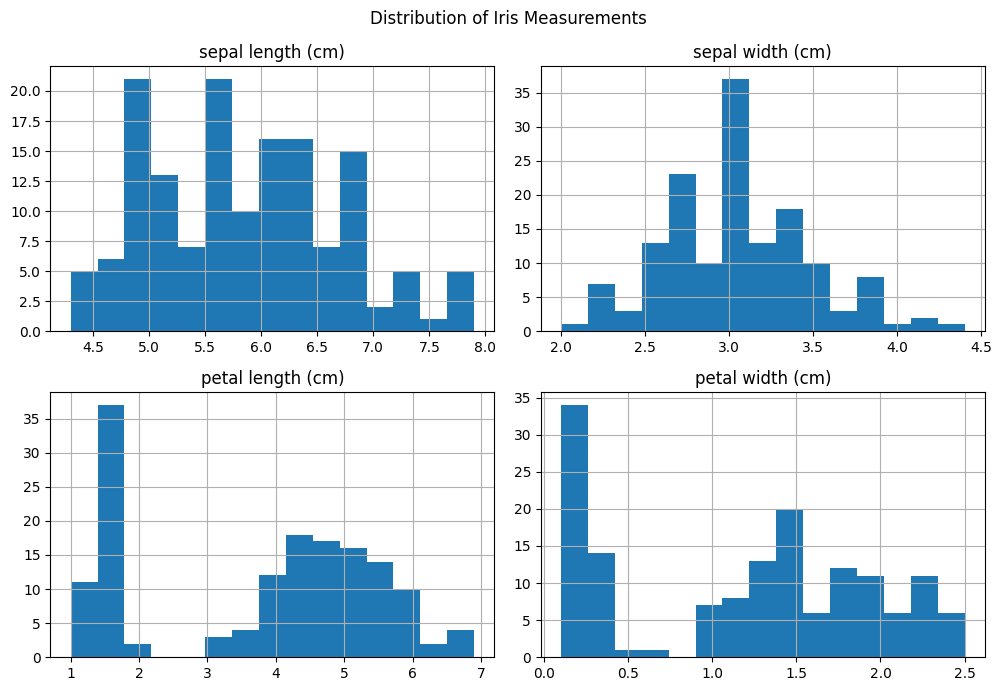

In [11]:
print("Missing values per column:")
display(df.isnull().sum())

print("\nClass counts:")
display(df["species"].value_counts())

df[iris.feature_names].hist(figsize=(10, 7), bins=15)
plt.suptitle("Distribution of Iris Measurements")
plt.tight_layout()
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 120
Testing examples: 30


In [13]:
model_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_pipeline.fit(X_train, y_train)
print("Model training complete!")

Model training complete!


Test accuracy: 93.33%

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



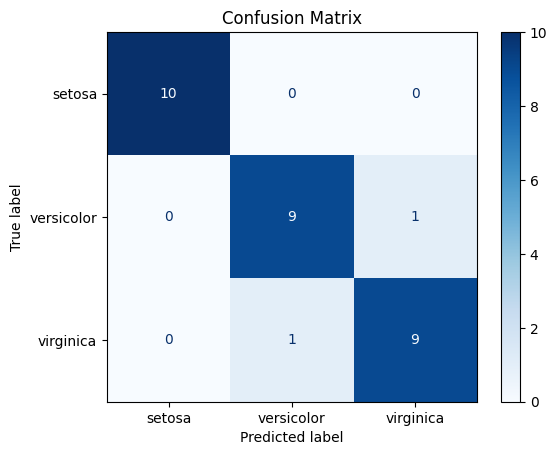

In [6]:
y_pred = model_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.2%}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

In [7]:
# Example measurements in the same feature order as the dataset:
# sepal length, sepal width, petal length, petal width (cm)
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

predicted_class = model_pipeline.predict(new_flower)[0]
predicted_species = iris.target_names[predicted_class]
probabilities = model_pipeline.predict_proba(new_flower)[0]

print("Predicted species:", predicted_species)
print("Class probabilities:")
for name, probability in zip(iris.target_names, probabilities):
    print(f"  {name}: {probability:.1%}")

Predicted species: setosa
Class probabilities:
  setosa: 98.1%
  versicolor: 1.9%
  virginica: 0.0%


## 9. ML pipeline recap

**Problem → Data → EDA → Train/test split → Preprocessing → Model training → Evaluation → Prediction → Save model**


- Features (`X`) are the measurements used as input.
- The target (`y`) is the species label.
- A train/test split helps evaluate generalization.
- A pipeline keeps preprocessing and prediction steps together.
- Metrics and a confusion matrix help assess model performance.

1. Change `test_size=0.20` to `0.30`. Does the score change?
2. Replace `LogisticRegression` with `DecisionTreeClassifier` (import it first).
3. Try different measurements in `new_flower`.
4. Compare accuracy with precision/recall; do not judge a model by accuracy alone.

**Important:** This is an educational toy project, not a production system.

In [8]:
model_path = "iris_classifier_pipeline.joblib"
joblib.dump(model_pipeline, model_path)
print(f"Saved model to: {model_path}")

# Optional: load it back and check a prediction
loaded_model = joblib.load(model_path)
print("Prediction from loaded model:", iris.target_names[loaded_model.predict(new_flower)[0]])

Saved model to: iris_classifier_pipeline.joblib
Prediction from loaded model: setosa
